In [1]:
import sys
sys.path.insert(0, "../")

import matplotlib.pyplot as plt
import numpy as np
from src.Heat1DCrankNicolson import Heat1DCrankNicolson

plt.style.use("../styles/plots.mplstyle")
np.random.seed(42)

In [2]:
dt = 0.005
L = 1
nt = 2000
Tf = dt * nt
D = 1
wanted_r = 0.72
h = 1

# Inizializza solver
solver = Heat1DCrankNicolson(L,Tf,nt,D,h,wanted_r=wanted_r)
solver.info()

# Compute impulse response
g = solver.impulse_response()[-1,:]


-----------------------------Solver info------------------------------

Diffusion time:                                               1.00e+00
dx:                                                           9.09e-02
dt:                                                           5.00e-03
nt:                                                               2000
nx:                                                                 12
r:                                                            6.05e-01
h:                                                            1.00e+00


In [3]:
from scipy.optimize import brentq

def f_eigen(x, h, L):
    return x + h * np.tan(x * L)

def trova_radici(h, L, n_radici):
    radici = []
    k = 0
    while len(radici) < n_radici:
        # Per x + h*tan(xL)=0 con h>0 le radici stanno dove tan < 0,
        # cioè in ( (2k+1)π/(2L) , (k+1)π/L )
        left_asym  = (2*k + 1) * np.pi / (2*L)   # asintoto sinistro
        right_zero = (k + 1)   * np.pi / L        # zero di tan
        
        a = left_asym  + 1e-9
        b = right_zero - 1e-9

        try:
            fa, fb = f_eigen(a, h, L), f_eigen(b, h, L)
            if fa * fb < 0:
                root = brentq(f_eigen, a, b, args=(h, L))
                radici.append(root)
        except Exception:
            pass
        k += 1
    return np.array(radici)

radici = trova_radici(h, L, 3)
radici_squared = radici*radici

print(radici)

[2.02875784 4.91318044 7.97866571]


In [5]:
from scipy.optimize import curve_fit

def func(x, a, q):
    return a*np.exp(-q*x)
    
popt, pcov = curve_fit(func, solver.t_array[1000:], g[1000:], p0=(1,(radici[0]*radici[0])/D))

print(popt)
# a = amplitude
# q = lambda_0^2 * D  →  lambda_0 = sqrt(q/D)
print(f"q fit:         {popt[1]:.6f}")
print(f"lambda_0^2 * D:    {radici[0]**2 * D:.6f}")
print(f"lambda_0 fit:  {np.sqrt(popt[1]/D):.6f}")
print(f"lambda_0 theory:  {radici[0]:.6f}")

[3.06323574 4.10991704]
q fit:         4.109917
lambda_0^2 * D:    4.115858
lambda_0 fit:  2.027293
lambda_0 theory:  2.028758


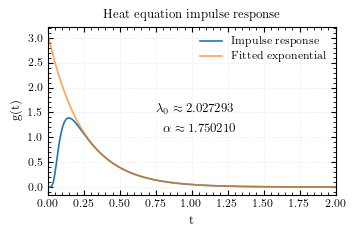

In [7]:
plt.figure()

plt.plot(solver.t_array[:], g[:], label="Impulse response")
plt.plot(solver.t_array[:], func(solver.t_array[:],*popt), label="Fitted exponential", alpha = 0.7)
plt.text(0.75,1.5, fr"$\lambda_0 \approx {np.sqrt(popt[1]*D):.6f}$")
plt.text(0.8,1.1, fr"$\alpha \approx {np.sqrt(popt[0]):.6f}$")

plt.legend()
#plt.ylim([0,1.5])
plt.xlim([0,2])
plt.grid()
plt.title("Heat equation impulse response")

plt.xlabel("t")
plt.ylabel("g(t)")
plt.minorticks_on()
plt.savefig("../assets/exponential_fit_impulse_response.pdf")
plt.show()

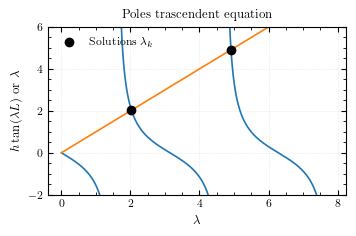

In [8]:
epsilon = 0.001
x_array_plot_1 = np.linspace(0,np.pi/2-epsilon,1000)
x_array_plot_2 = np.linspace(np.pi/2+epsilon,3/2*np.pi-epsilon,1000)
x_array_plot_3 = np.linspace(3*np.pi/2+epsilon,5/2*np.pi-epsilon,1000)

plt.figure()   

plt.plot(x_array_plot_1, -h*np.tan(x_array_plot_1*L), color="C0")
plt.plot(x_array_plot_2, -h*np.tan(x_array_plot_2*L), color="C0")
plt.plot(x_array_plot_3, -h*np.tan(x_array_plot_3*L), color="C0")

plt.plot(np.linspace(0,5/2*np.pi-epsilon,1000),np.linspace(0,5/2*np.pi-epsilon,1000), color="C1")

plt.scatter(radici[0], radici[0], c="k", zorder=3, label=r"Solutions $\lambda_k$")
plt.scatter(radici[1], radici[1], c="k", zorder=3)

plt.xlabel(r"$\lambda$")
plt.ylabel(r"$h\tan(\lambda L)$ or $\lambda$")
plt.title("Poles trascendent equation")
plt.grid()
plt.minorticks_on()
plt.legend()
plt.ylim([-2,6])
plt.savefig("../assets/trascendent_equation_solutions.pdf")

### Compute g via impulse response

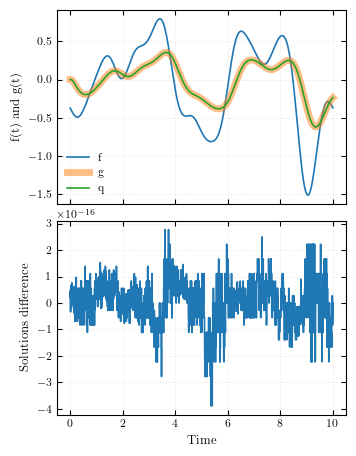

In [10]:
from src.FunctionsGenerator import FunctionsGenerator

generator = FunctionsGenerator(solver.t_array, l = solver.Tf/20, sigma = 1)

impulse_response = solver.impulse_response()[-1,:]

f = generator.generate_from_white_noise()
g = solver.solve_from_impulse_response(f,impulse_response)
q = solver.solve(f)[-1,:]

fig, axes = plt.subplots(2,1,figsize=(3.4, 4.4), sharex=True)

axes[0].plot(solver.t_array, f, label="f")
axes[0].plot(solver.t_array, g, label="g", lw=5, alpha=0.5)
axes[0].plot(solver.t_array, q, label="q")
axes[0].set_ylabel("f(t) and g(t)")

axes[0].legend()

axes[0].grid()
axes[1].grid()

axes[1].plot(solver.t_array,(q-g))

axes[1].set_ylabel("Solutions difference")
axes[1].set_xlabel("Time")

plt.savefig("../assets/impulse_response_reconstruction_numerical_error.pdf")
plt.show()
    